# σ70 Promoter Calculator validation (2×2)

Each promoter element perturbed by the variable it actually depends on — justifies
using the Promoter Calculator to score generated σ70 promoters.

- **A** −35/−10 boxes — sequence  (real / distal / proximal / TSS / combos)
- **B** spacer — length (14→20 bp; optimum 17)
- **C** UP element — composition (Real / GC-rich / AT-rich)
- **D** TSS — position (predicted − RegulonDB TSS)

Sources: `pc_ablation_sigma70.csv`, `pc_spacer_length_results.csv`,
`pc_up_gc_results.csv`, `pc_tss_control_results.csv`.


TSS: median +1 bp, 80% within +/-3 (n=451)


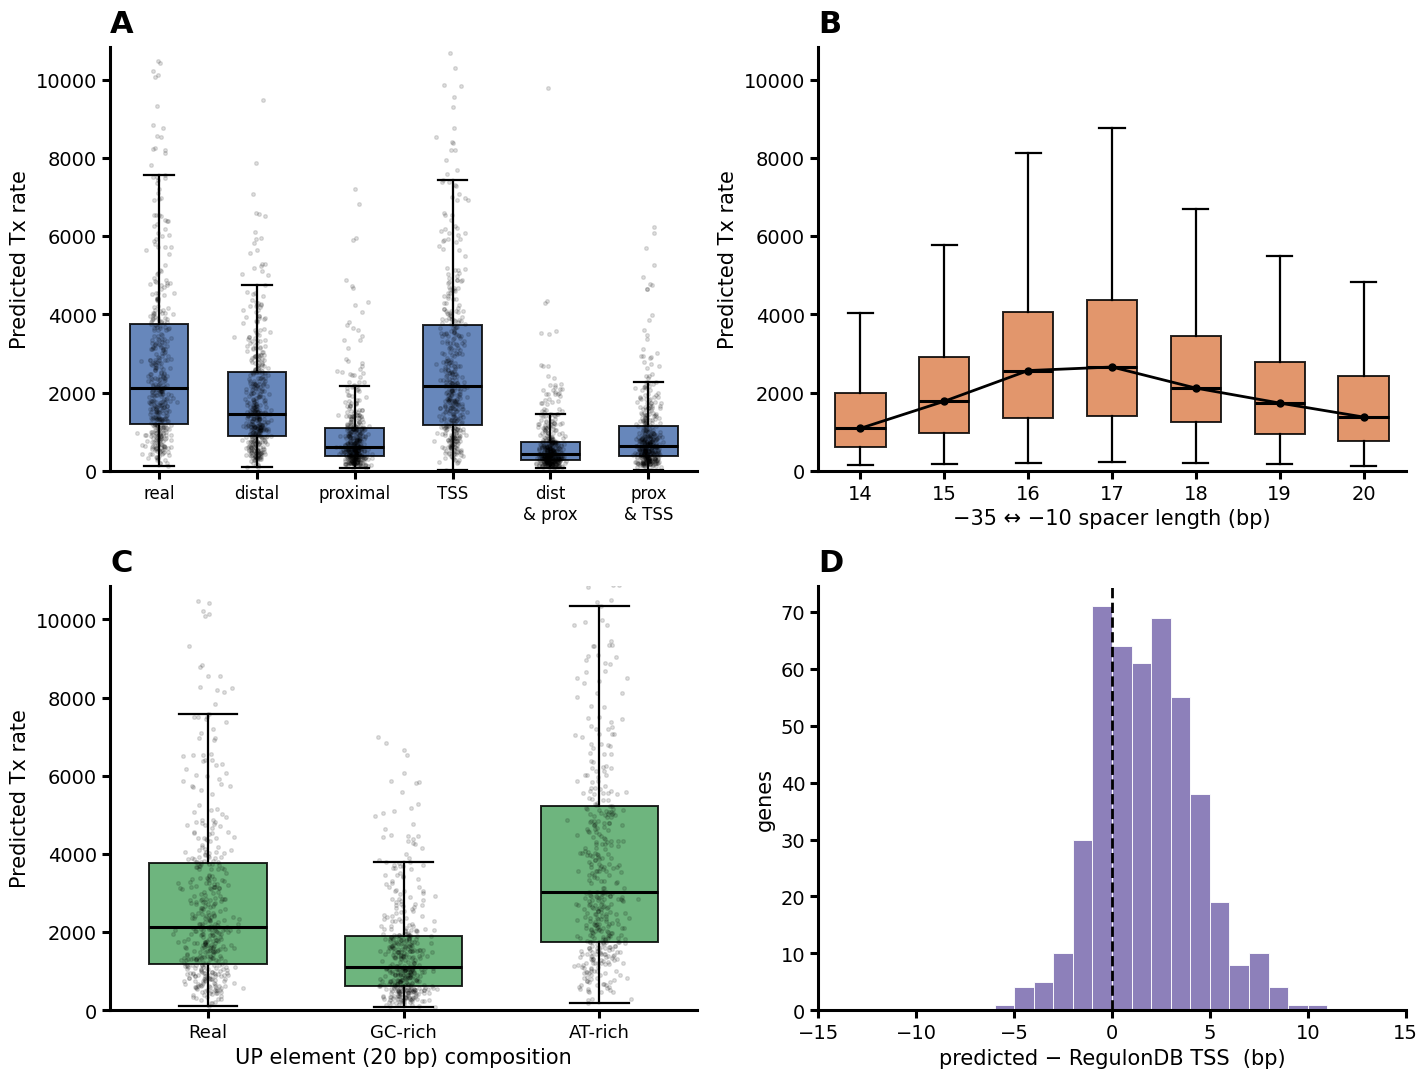

saved fig_sigma70_validation.png / .pdf


In [1]:
import csv
import numpy as np
import matplotlib.pyplot as plt

def rows(f): return list(csv.DictReader(open(f)))
def arr(rs, k): return np.array([float(r[k]) for r in rs if r.get(k, "") not in ("", "nan")])

# publication style — thick axes, big fonts
plt.rcParams.update({
    "font.size": 14, "axes.linewidth": 2.2,
    "xtick.major.width": 2.2, "ytick.major.width": 2.2,
    "xtick.major.size": 6, "ytick.major.size": 6,
    "font.family": "DejaVu Sans", "savefig.bbox": "tight",
})
# palatable, distinct colour per panel
COL = {"A": "#4C72B0", "B": "#DD8452", "C": "#55A868", "D": "#8172B3"}

ab = rows("pc_ablation_sigma70.csv")
sp = rows("pc_spacer_length_results.csv")
up = rows("pc_up_gc_results.csv")
ts = rows("pc_tss_control_results.csv")

def style_box(bp, color):
    for b in bp["boxes"]:
        b.set_facecolor(color); b.set_alpha(0.85); b.set_edgecolor("black"); b.set_linewidth(1.4)
    for w in bp["whiskers"] + bp["caps"]: w.set_linewidth(1.6)
def letter(a, L): a.text(0.0, 1.02, L, transform=a.transAxes, fontsize=22, fontweight="bold", va="bottom", ha="left")
def upper_whisker(d):
    q1, q3 = np.percentile(d, [25, 75]); top = q3 + 1.5 * (q3 - q1)
    ins = d[d <= top]; return ins.max() if len(ins) else d.max()

fig, ax = plt.subplots(2, 2, figsize=(14.5, 11))
rng = np.random.default_rng(0)

# ---- A) boxes: sequence ----
BC = ["Real", "distal", "proximal", "TSS", "distal+proximal", "proximal+TSS"]
BL = ["real", "distal", "proximal", "TSS", "dist\n& prox", "prox\n& TSS"]
Adata = [arr([r for r in ab if r["condition"] == c], "Tx_rate") for c in BC]
bp = ax[0,0].boxplot(Adata, patch_artist=True, showfliers=False, whis=1.5, widths=0.6, medianprops=dict(color="black", lw=2.2))
style_box(bp, COL["A"])
for i, d in enumerate(Adata, 1): ax[0,0].scatter(rng.normal(i, 0.06, len(d)), d, s=7, color="black", alpha=0.12, zorder=3)
ax[0,0].set_xticks(range(1, len(BC)+1)); ax[0,0].set_xticklabels(BL, fontsize=12)
ax[0,0].set_ylabel("Predicted Tx rate", fontsize=15); letter(ax[0,0], "A")

# ---- B) spacer: length ----
LENS = [14,15,16,17,18,19,20]
Bdata = [arr([r for r in sp if r["spacer_len"] == str(L)], "Tx_rate") for L in LENS]
bp = ax[0,1].boxplot(Bdata, patch_artist=True, showfliers=False, whis=1.5, widths=0.6, positions=LENS, medianprops=dict(color="black", lw=2.2))
style_box(bp, COL["B"])
ax[0,1].plot(LENS, [np.median(d) for d in Bdata], "-o", color="black", lw=2, ms=5, zorder=4)
ax[0,1].set_xlabel("−35 ↔ −10 spacer length (bp)", fontsize=15)
ax[0,1].set_ylabel("Predicted Tx rate", fontsize=15); letter(ax[0,1], "B")

# ---- C) UP: composition ----
UC = ["Real", "GC-rich", "AT-rich"]
Cdata = [arr([r for r in up if r["up_condition"] == c], "Tx_rate") for c in UC]
bp = ax[1,0].boxplot(Cdata, patch_artist=True, showfliers=False, whis=1.5, widths=0.6, medianprops=dict(color="black", lw=2.2))
style_box(bp, COL["C"])
for i, d in enumerate(Cdata, 1): ax[1,0].scatter(rng.normal(i, 0.06, len(d)), d, s=7, color="black", alpha=0.12, zorder=3)
ax[1,0].set_xticks([1,2,3]); ax[1,0].set_xticklabels(UC, fontsize=13)
ax[1,0].set_xlabel("UP element (20 bp) composition", fontsize=15)
ax[1,0].set_ylabel("Predicted Tx rate", fontsize=15); letter(ax[1,0], "C")

# shared y for A,B,C, high enough to show all whisker caps (fix clipped outliers)
ymax = max(upper_whisker(d) for d in Adata + Bdata + Cdata if len(d)) * 1.05
for a in (ax[0,0], ax[0,1], ax[1,0]): a.set_ylim(0, ymax)

# ---- D) TSS: position ----
off = arr([r for r in ts if r["condition"] == "Real"], "tss_offset")
print(f"TSS: median +{int(np.median(off))} bp, {100*np.mean(np.abs(off)<=3):.0f}% within +/-3 (n={len(off)})")
ax[1,1].hist(off, bins=range(-15,16), color=COL["D"], edgecolor="white", linewidth=0.7, alpha=0.9)
ax[1,1].axvline(0, ls="--", color="black", lw=2)
ax[1,1].set_xlim(-15,15)
ax[1,1].set_xlabel("predicted − RegulonDB TSS  (bp)", fontsize=15)
ax[1,1].set_ylabel("genes", fontsize=15); letter(ax[1,1], "D")

for a in ax.ravel(): a.spines[["top","right"]].set_visible(False); a.tick_params(width=2.2)
plt.tight_layout()
plt.savefig("fig_sigma70_validation.png", dpi=300); plt.savefig("fig_sigma70_validation.pdf"); plt.show()
print("saved fig_sigma70_validation.png / .pdf")